# Figure 12 — qReduMIS vs number of quantum shots

Effect of the number of quantum shots per QPU call ($\mathrm{qshots}$) on qReduMIS (QAOA $p=2$, H2-1 emulator)
for the NIKKEI 225 market-graph instance $N=30$, seed $=63$ (kernel $K=16$, $|\mathrm{MIS}|=10$).

- **Fig. 12** (`figures/qshots_sweep_N30_seed63_overview.png`): success probability $P_{\mathrm{MIS}}$ (95% Wilson CI),
  optTTS (with the linear reference $\propto \mathrm{qshots}$) and average approximation ratio $\langle|IS|\rangle/|\mathrm{MIS}|$.
- Numbers quoted in the text: hardness $\mathbb{H}=3.375$, standalone QAOA success probability on the kernel ($0.4\%$),
  probability of sampling the optimum with 5 shots ($\sim 2\%$), and $P_{\mathrm{MIS}}=0.35$ at $\mathrm{qshots}=5$.

In [1]:
%matplotlib inline
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Release root (for utils/)
_REL_ROOT = os.getcwd() if os.path.isdir("consolidated_results") else os.path.abspath(os.pardir)  # release root (re-run safe)
sys.path.insert(0, _REL_ROOT)

from utils.opt_tts_estimator import estimate_opt_tts, load_ground_truth
from utils.derived import DerivedData

D = DerivedData()   # consolidated tables under consolidated_results/

plt.rcParams.update({
    'font.size': 14, 'axes.titlesize': 16, 'axes.labelsize': 14,
    'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 12,
})

# ── Configuration ────────────────────────────────────────────────────
BASE = _REL_ROOT
os.chdir(BASE)  # resolve relative paths from the release root

SAVE_FIGURES = False  # set False to skip saving figures
os.makedirs("figures", exist_ok=True)

SWEEP_DIR = os.path.join(BASE, "results/qshots_sweep/N30_seed63")
RUN_DATE = "2026-04-28"

QSHOTS_VALUES = [5, 10, 20, 50, 100, 200]
N_INSTANCE = 30
SEED_INSTANCE = 63
GT_MIS_FULL = 10      # ground-truth MIS for the full graph
GT_MIS_KERNEL = 4     # ground-truth MIS for the kernel
P_QAOA = 2

# Graph directories (for the optTTS estimator)
GRAPH_DIR = [
    os.path.join(BASE, "problem_instances/market"),
    os.path.join(BASE, "problem_instances/market_extra"),
]

# Ground truth
GT_PATH = os.path.join(BASE, "problem_instances/registries/ground_truth_testbed.json")
gt_full = load_ground_truth(GT_PATH, mis_key="mis_full")

# Bootstrap parameters
N_BOOT = 1_000
P_D = 0.99

RESULT_DIRS = {
    qs: os.path.join(SWEEP_DIR, f"qredumis_p{P_QAOA}_qshots{qs}_{RUN_DATE}")
    for qs in QSHOTS_VALUES
}
for qs, rd in RESULT_DIRS.items():
    _ok = D.db_available(os.path.join(rd, "benchmark_qredumis.db"))
    print(f"  qshots={qs:>3d}: {'OK' if _ok else 'MISSING'} {os.path.relpath(rd, BASE)}")


  qshots=  5: OK results/qshots_sweep/N30_seed63/qredumis_p2_qshots5_2026-04-28
  qshots= 10: OK results/qshots_sweep/N30_seed63/qredumis_p2_qshots10_2026-04-28
  qshots= 20: OK results/qshots_sweep/N30_seed63/qredumis_p2_qshots20_2026-04-28
  qshots= 50: OK results/qshots_sweep/N30_seed63/qredumis_p2_qshots50_2026-04-28
  qshots=100: OK results/qshots_sweep/N30_seed63/qredumis_p2_qshots100_2026-04-28
  qshots=200: OK results/qshots_sweep/N30_seed63/qredumis_p2_qshots200_2026-04-28


## Load the qshots sweep

In [2]:
# ═══════════════════════════════════════════════════════════════
# Collect all metrics for each qshots value
# ═══════════════════════════════════════════════════════════════

records = []

for qs in QSHOTS_VALUES:
    rdir = RESULT_DIRS[qs]
    db_path = os.path.join(rdir, "benchmark_qredumis.db")

    # ── 1. Per-cshot MIS size + iterations (derived) ──────────────
    mis_sizes = []
    iterations = []
    for d in D.db_records(db_path):
        mis_sizes.append(len(d["atom positions MIS"]))
        iterations.append(d["num iteration"])

    n_cshots = len(mis_sizes)
    n_success = sum(1 for s in mis_sizes if s == GT_MIS_FULL)
    p_success = n_success / n_cshots if n_cshots else 0.0
    mean_iter = np.mean(iterations)

    # ── 2. Approximation ratio (best MIS found / GT) ───────────
    best_mis = max(mis_sizes)
    approx_ratio = best_mis / GT_MIS_FULL

    # ── 3. Weighted avg IS (final |W| per cshot) ───────────────
    inter_dir = os.path.join(rdir, "intermediate_iterations")
    w_sizes = list(D.final_W_by_cshot(inter_dir).values())

    weighted_avg_IS = np.mean(w_sizes)
    weighted_ar = weighted_avg_IS / GT_MIS_FULL

    # ── 4. optTTS via estimator (cost_per_call = qshots) ───────
    df_tts = estimate_opt_tts(
        graph_dir=GRAPH_DIR,
        results_dir=rdir,
        method_type="redumis",
        cost_per_call=float(qs),
        ground_truth=gt_full,
        n_boot=N_BOOT,
        p_d=P_D,
        verbose=False,
    )

    if len(df_tts) > 0:
        row = df_tts.iloc[0]
        opt_tts = row["boot_median"]
        opt_tts_lo = row.get("ci_lo", np.nan)
        opt_tts_hi = row.get("ci_hi", np.nan)
        mean_opt_calls = row.get("mean_opt_calls", np.nan)
    else:
        opt_tts = np.nan
        opt_tts_lo = np.nan
        opt_tts_hi = np.nan
        mean_opt_calls = np.nan

    rec = {
        "qshots": qs,
        "n_cshots": n_cshots,
        "p_success": p_success,
        "approx_ratio": approx_ratio,
        "weighted_ar": weighted_ar,
        "weighted_avg_IS": weighted_avg_IS,
        "mean_iterations": mean_iter,
        "mean_opt_calls": mean_opt_calls,
        "opt_tts": opt_tts,
        "opt_tts_ci_lo": opt_tts_lo,
        "opt_tts_ci_hi": opt_tts_hi,
        "best_mis": best_mis,
    }
    records.append(rec)
    print(f"qshots={qs:>3d}:  p_s={p_success:.3f}  AR={approx_ratio:.3f}  "
          f"⟨|W|⟩/MIS={weighted_ar:.3f}  optTTS={opt_tts:.2f}  "
          f"mean_iter={mean_iter:.2f}  mean_opt_calls={mean_opt_calls:.2f}")

df = pd.DataFrame(records)
df

qshots=  5:  p_s=0.350  AR=1.000  ⟨|W|⟩/MIS=0.930  optTTS=58.58  mean_iter=1.05  mean_opt_calls=1.00
qshots= 10:  p_s=0.500  AR=1.000  ⟨|W|⟩/MIS=0.950  optTTS=71.47  mean_iter=1.05  mean_opt_calls=1.00


qshots= 20:  p_s=0.650  AR=1.000  ⟨|W|⟩/MIS=0.965  optTTS=93.90  mean_iter=1.05  mean_opt_calls=1.00
qshots= 50:  p_s=0.550  AR=1.000  ⟨|W|⟩/MIS=0.955  optTTS=309.30  mean_iter=1.25  mean_opt_calls=1.00


qshots=100:  p_s=0.800  AR=1.000  ⟨|W|⟩/MIS=0.980  optTTS=308.73  mean_iter=1.10  mean_opt_calls=1.00
qshots=200:  p_s=0.900  AR=1.000  ⟨|W|⟩/MIS=0.990  optTTS=442.92  mean_iter=1.10  mean_opt_calls=1.00


,qshots,n_cshots,p_success,approx_ratio,weighted_ar,weighted_avg_IS,mean_iterations,mean_opt_calls,opt_tts,opt_tts_ci_lo,opt_tts_ci_hi,best_mis
0,5,20,0.35,1.0,0.930,9.30,1.05,1.0,58.583603,30.930412,172.437735,10
1,10,20,0.50,1.0,0.950,9.50,1.05,1.0,71.469233,35.671779,180.671252,10
2,20,20,0.65,1.0,0.965,9.65,1.05,1.0,93.903606,52.842815,166.436322,10
3,50,20,0.55,1.0,0.955,9.55,1.25,1.0,309.304124,178.358893,585.836030,10
4,100,20,0.80,1.0,0.980,9.80,1.10,1.0,308.728933,177.787459,538.197100,10
5,200,20,0.90,1.0,0.990,9.90,1.10,1.0,442.923746,249.678540,713.435572,10


## Fig. 12 — success probability, optTTS and average approximation ratio vs qshots

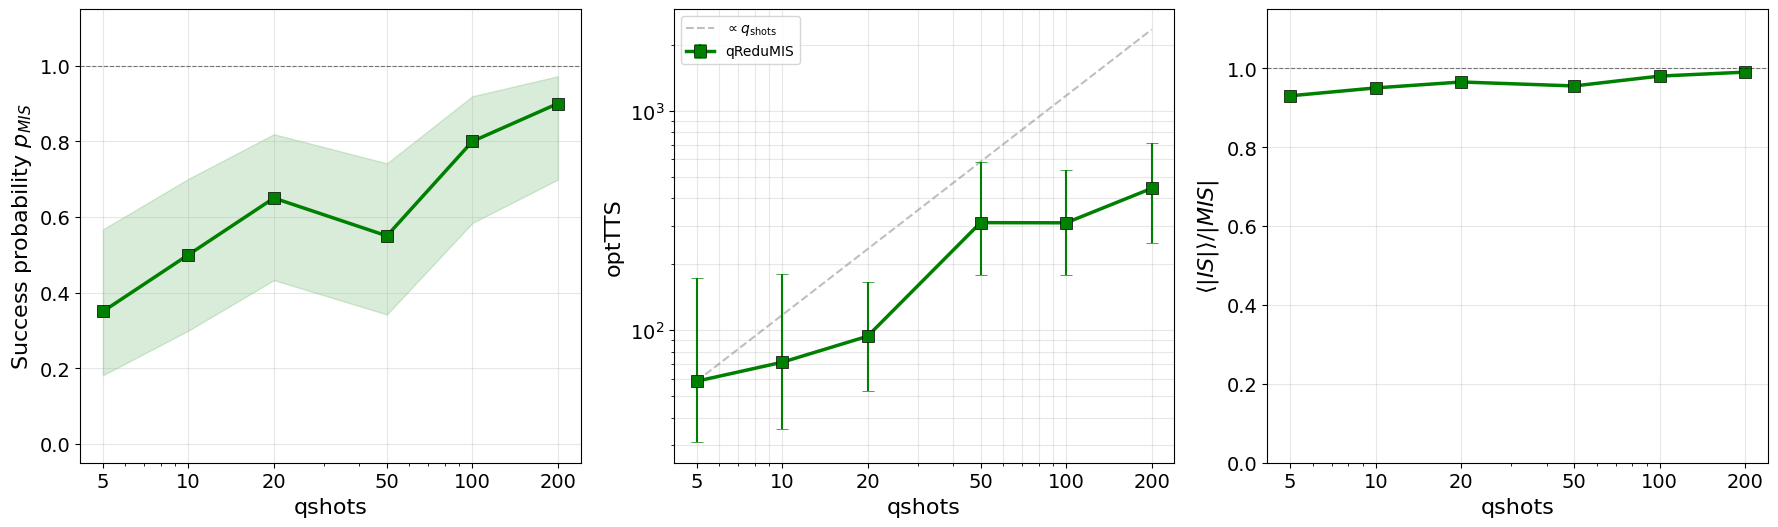

In [3]:
# ═══════════════════════════════════════════════════════════════
# Fig. 12 -- p_MIS, optTTS, average AR vs qshots
# ═══════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

marker_kw = dict(marker="s", color="green", markersize=9, linewidth=2.5,
                 markeredgecolor="k", markeredgewidth=0.5)

# ── Panel (a): Success probability ────────────────────────────
ax = axes[0]
ax.plot(df["qshots"], df["p_success"], "-", **marker_kw, label="qReduMIS")

# Wilson CI
z = 1.96
n_arr = df["n_cshots"].values.astype(float)
p_arr = df["p_success"].values
denom = 1 + z**2 / n_arr
centre = (p_arr + z**2 / (2 * n_arr)) / denom
margin = z * np.sqrt((p_arr * (1 - p_arr) + z**2 / (4 * n_arr)) / n_arr) / denom
ci_lo_w = np.clip(centre - margin, 0, 1)
ci_hi_w = np.clip(centre + margin, 0, 1)
ax.fill_between(df["qshots"], ci_lo_w, ci_hi_w,
                color="green", alpha=0.15)

ax.axhline(1.0, color="black", linewidth=0.8, linestyle="--", alpha=0.5)
ax.set_xscale("log")
ax.set_xticks(QSHOTS_VALUES)
ax.set_xticklabels([str(q) for q in QSHOTS_VALUES])
ax.set_ylim(-0.05, 1.15)
ax.set_xlabel("qshots", fontsize=16)
ax.set_ylabel("Success probability $p_{MIS}$", fontsize=16)
ax.grid(True, alpha=0.3)

# ── Panel (b): optTTS ─────────────────────────────────────────
ax = axes[1]
valid = df[np.isfinite(df["opt_tts"])].copy()
yerr_lo = (valid["opt_tts"] - valid["opt_tts_ci_lo"]).clip(lower=0).values
yerr_hi = (valid["opt_tts_ci_hi"] - valid["opt_tts"]).clip(lower=0).values

ax.errorbar(valid["qshots"], valid["opt_tts"],
            yerr=[yerr_lo, yerr_hi],
            fmt="s-", color="green", markersize=9, linewidth=2.5,
            markeredgecolor="k", markeredgewidth=0.5,
            ecolor="green", elinewidth=1.5, capsize=4, capthick=1.5,
            label="qReduMIS", zorder=5)

# Linear reference
if len(valid) >= 2:
    q0, t0 = valid["qshots"].values[0], valid["opt_tts"].values[0]
    q_range = np.linspace(min(QSHOTS_VALUES), max(QSHOTS_VALUES), 100)
    ax.plot(q_range, t0 * (q_range / q0),
            "--", color="gray", alpha=0.5, linewidth=1.5,
            label=r"$\propto q_{\mathrm{shots}}$")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(QSHOTS_VALUES)
ax.set_xticklabels([str(q) for q in QSHOTS_VALUES])
ax.set_xlabel("qshots", fontsize=16)
ax.set_ylabel("optTTS", fontsize=16)
ax.legend(fontsize=10, frameon=True, loc="upper left")
ax.grid(True, alpha=0.3, which="both")

# ── Panel (c): Approximation ratio ───────────────────────────
ax = axes[2]
ax.plot(df["qshots"], df["weighted_ar"],
        "s-", color="green", markersize=9, linewidth=2.5,
        markeredgecolor="k", markeredgewidth=0.5)

ax.axhline(1.0, color="black", linewidth=0.8, linestyle="--", alpha=0.5)
ax.set_xscale("log")
ax.set_xticks(QSHOTS_VALUES)
ax.set_xticklabels([str(q) for q in QSHOTS_VALUES])
ax.set_ylim(0.0, 1.15)
ax.set_xlabel("qshots", fontsize=16)
ax.set_ylabel(r"$\langle |IS| \rangle / |MIS|$", fontsize=16)
ax.grid(True, alpha=0.3)

plt.tight_layout()
if SAVE_FIGURES:
    plt.savefig("figures/qshots_sweep_N30_seed63_overview.png", dpi=300, bbox_inches="tight")
plt.show()

## Numbers quoted in the text: hardness $\mathbb{H}$ and standalone QAOA

In [4]:
# ═══════════════════════════════════════════════════════════════
# Hardness parameter H = D(MIS-1) / (|MIS| * D(MIS)) of the kernel
# ═══════════════════════════════════════════════════════════════
def _find_repo_root(start=None):
    """Walk up to the folder holding pyproject.toml and the qReduMIS package."""
    d = os.path.abspath(start or os.getcwd())
    while d != os.path.dirname(d):
        if os.path.isfile(os.path.join(d, 'pyproject.toml')) and (
                os.path.isdir(os.path.join(d, 'qReduMIS_package'))
                or os.path.isdir(os.path.join(d, 'qReduMIS'))):
            return d
        d = os.path.dirname(d)
    raise RuntimeError('Could not locate qReduMIS repo root')

# networkx 2.8.8 references NumPy aliases removed in NumPy 2.0.
for _legacy, _modern in (("float_", "float64"), ("int_", "int64"),
                         ("complex_", "complex128"), ("unicode_", "str_")):
    if not hasattr(np, _legacy):
        setattr(np, _legacy, getattr(np, _modern))
import networkx as nx
from copy import deepcopy

sys.path.insert(0, _find_repo_root())
from utils.mis_degeneracy import analyze_graph
from qReduMIS.solver.classical_reducer.reducer import Reducer

G = nx.read_graphml(os.path.join(BASE, "problem_instances/market_extra", f"graphs_N{N_INSTANCE}",
                                 f"graph_unweighted_{SEED_INSTANCE}.graphml"))
kernel, removed, selected = Reducer(verbose=False).reduce(deepcopy(G))
res = analyze_graph(kernel, GT_MIS_KERNEL, compute_mis_minus_1=True)
H = res["deg_mis_minus_1"] / (GT_MIS_KERNEL * res["deg_mis"])

print(f"Full graph: {G.number_of_nodes()} nodes;  kernel K = {kernel.number_of_nodes()} nodes, "
      f"density = {nx.density(kernel):.4f}")
print(f"D(MIS={GT_MIS_KERNEL}) = {res['deg_mis']},  D(MIS-1) = {res['deg_mis_minus_1']}")
print(f"Hardness H = {H:.4f}")


Full graph: 30 nodes;  kernel K = 16 nodes, density = 0.6667
D(MIS=4) = 2,  D(MIS-1) = 27
Hardness H = 3.3750


In [5]:
# ═══════════════════════════════════════════════════════════════
# Standalone QAOA (p=2, 500 shots on the kernel) vs qReduMIS with qshots=5
# ═══════════════════════════════════════════════════════════════
QAOA_DB = os.path.join(BASE, "results/emulator_nikkei/remove_only", "qaoa_p2_2026-04-27", "benchmark_qaoa.db")
p_qaoa = next(d["pmis"] for d in D.db_records(QAOA_DB)
              if (d["N"], d["seed"]) == (N_INSTANCE, SEED_INSTANCE))

p5 = df.loc[df["qshots"] == 5].iloc[0]
print(f"Standalone QAOA p=2 success probability on the kernel: {p_qaoa:.4f} ({100 * p_qaoa:.1f}%)")
print(f"P(sampling the optimum at least once in 5 QAOA shots) = 1 - (1 - p)^5 = {1 - (1 - p_qaoa) ** 5:.4f}")
print(f"qReduMIS with qshots=5: P_MIS = {p5['p_success']:.2f}, "
      f"mean QPU calls to solution = {p5['mean_opt_calls']:.2f}, mean QPU calls = {p5['mean_iterations']:.2f}")


Standalone QAOA p=2 success probability on the kernel: 0.0040 (0.4%)
P(sampling the optimum at least once in 5 QAOA shots) = 1 - (1 - p)^5 = 0.0198
qReduMIS with qshots=5: P_MIS = 0.35, mean QPU calls to solution = 1.00, mean QPU calls = 1.05
